# Lab 5: Perceptual modeling
Explore different perceptual masking topics used in audio coding.

## References:

### Bark scale
The Bark scale is a perceptual scale that divides the audible frequency range into critical bands, based on how the human ear perceives sound. 

### Critical bands
The Bark scale divides the audible frequency spectrum (roughly 20 Hz to 20,000 Hz) into 24 critical bands. Each critical band corresponds to a range of frequencies that the human ear processes as a single unit. Within a critical band, multiple sound frequencies can interact, leading to auditory masking (one sound making another sound less audible).

### Masking threshold in quiet
The masking threshold in quiet refers to the minimum sound intensity level at a specific frequency that is audible to the human ear in a quiet environment, with no background noise. This threshold is important in psychoacoustics, as it defines the point at which a sound becomes detectable by a listener in an ideal, quiet setting.

### Frequency masking
Frequency masking is a psychoacoustic phenomenon where a louder sound at a certain frequency makes it difficult or impossible to hear a quieter sound at a nearby frequency. Essentially, when two sounds occur simultaneously but at different frequencies, the louder sound can "mask" or cover up the quieter one, especially if they are close in frequency. This effect plays a crucial role in how humans perceive complex sound environments.

### Spreading function
The spreading function refers to a model used in psychoacoustics to describe how masking effects spread across frequencies. It quantifies how the influence of a louder sound at a specific frequency spreads and affects the perception of quieter sounds across nearby frequencies. 

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import IPython.display as ipd
from scipy.io.wavfile import read
import scipy.signal as signal
from scipy.fftpack import fft, ifft


## Part 1 - Bark Scale

Explore the Bark scale. Answer the questions given and modify the code as needed to support your answers.

In [4]:
def read_sound(file):
  """ read a mono wav sound file, assuming is mono, and convert it to a floating point array
    Args:
      file (str): File name
    Returns:
      sound_array (numpy.array): Array of samples as floating point values between -1 and 1
      sampling_rate (int): Sampling rate
  """
  # read sound file
  sampling_rate, x = read(file)
  # convert to floating point values between -1 and 1, assuming x are 16 bit integers
  sound_array = np.float32(x) / 2**15
  return sound_array, sampling_rate

def display_sound(sound_array, sampling_rate=44100, title=None):
  """ Display signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      sampling_rate (int): Sampling rate
  """
  # plot the waveform of the sound
  plt.figure(0, figsize=(10, 2))
  time_indexes = np.arange(0, sound_array.size/sampling_rate, 1.0/sampling_rate)
  plt.plot(time_indexes, sound_array)
  plt.xlabel('time (seconds)')
  plt.ylabel('amplitude')
  plt.title(title)
  plt.show()
  # play the sound
  ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate, normalize=False))

# Define the Bark scale conversion function
def hz2bark(f):
    """ Usage: Bark=hz2bark(f)
    f    : (ndarray)    Array containing frequencies in Hz.
    Returns  :
    Brk  : (ndarray)    Array containing Bark scaled values.
    """
    Brk = 6. * np.arcsinh(f/600.)
    return Brk

def bark2hz(Brk):
    """ Usage:
    Hz=bark2hs(Brk)
    Args     :
        Brk  : (ndarray)    Array containing Bark scaled values.
    Returns  :
        Fhz  : (ndarray)    Array containing frequencies in Hz.
    """

    Fhz = 600. * np.sinh(Brk/6.)
    return Fhz

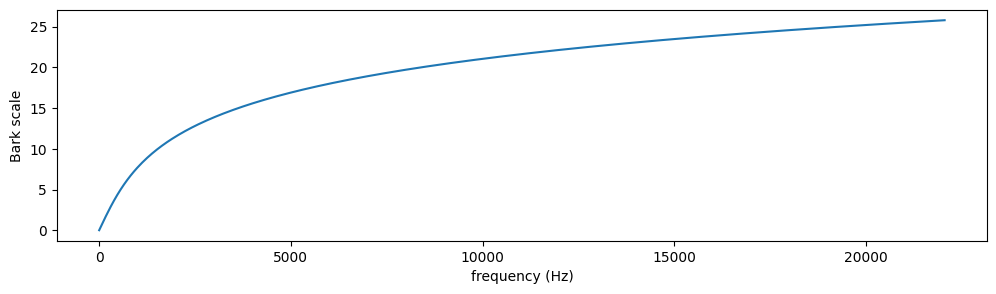

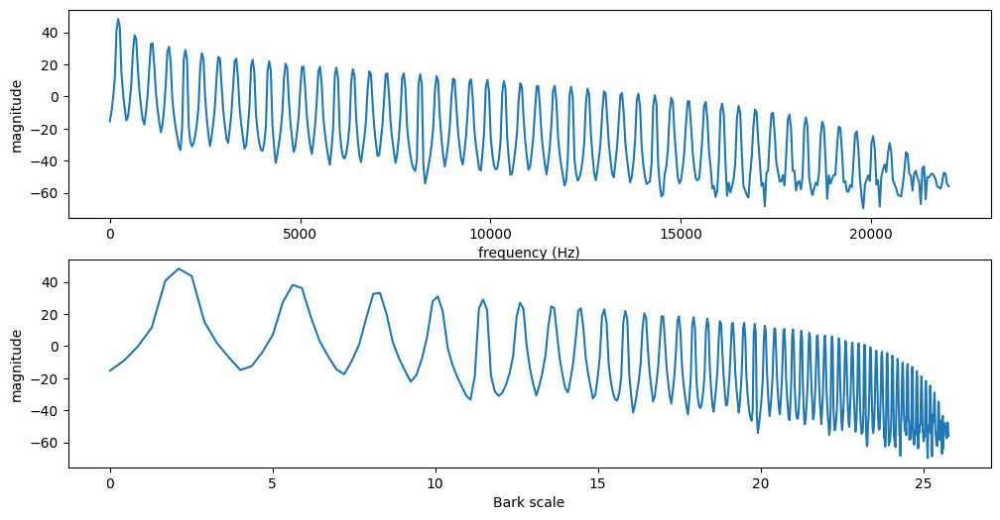

In [5]:
# compute and plot the bark scale

freqs = np.linspace(0,22050,512)
bark_scale = hz2bark(freqs)

# Plot the Bark scale
plt.figure(figsize=(12, 3))
plt.plot(freqs, bark_scale)
plt.xlabel("frequency (Hz)")
plt.ylabel("Bark scale")

# plot the magnitude spectrum of a sound in the bark scale
x, fs = read_sound('../sounds/synthetic.wav')
N = 1024
x1 = x[10000:10000+N]

# compute the hanning window
w = signal.get_window('hann', N)
# compute the spectrum of the windowed input signal
spectrum = fft(w*x1)
# compute the magnitude spectrum in dB
magnitude_spectrum = 20*np.log10(abs(spectrum[:N//2]))

# Plot the original FFT and the Bark scale spectrum
plt.figure(figsize=(12, 6))

bark_scale = hz2bark(freqs)

plt.subplot(2, 1, 1)
frequency_indexes =np.linspace(0,fs/2, N//2)
plt.plot(frequency_indexes, magnitude_spectrum)
plt.xlabel("frequency (Hz)")
plt.ylabel("magnitude")

plt.subplot(2, 1, 2)
plt.plot(bark_scale, magnitude_spectrum)
plt.xlabel("Bark scale")
plt.ylabel("magnitude")

plt.show()

<font color=red> ***MY MODIFIED CODE*** </font>

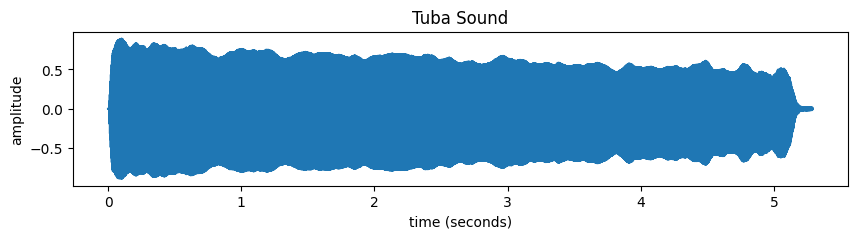

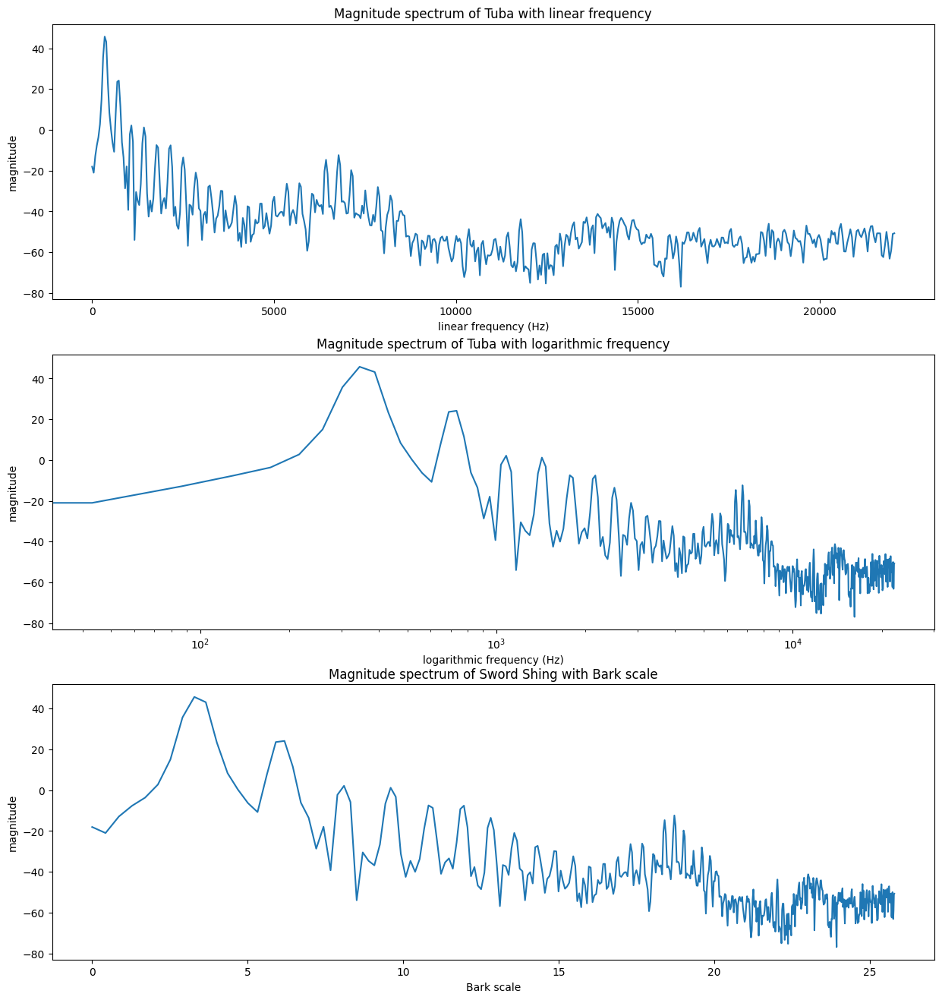

In [6]:
## COMPUTING THE MAGNITUDE SPECTRUM OF THE SOUND SYNTHETIC WITH LINEAR AND LOGARITHMIC FREQUENCY USING THE BARK SCALE

#Step 01: Computing the bark scale
freqs = np.linspace(0,22050,512)
bark_scale = hz2bark(freqs)

# Step 02: Reading and displaying the sound
x, fs = read_sound('../sounds/406609-tuba.wav')
N = 1024
x1 = x[10000:10000+N]
display_sound(x, fs, "Tuba Sound")

# Step 03: Computing the magnitude spectrum
w = signal.get_window('hann', N)
spectrum = fft(w*x1)
magnitude_spectrum = 20*np.log10(abs(spectrum[:N//2]))

# Step 04: Linear, logarithmic and bark scale
plt.figure(figsize=(15, 16))

plt.subplot(3, 1, 1)
frequency_indexes =np.linspace(0,fs/2, N//2)
plt.plot(frequency_indexes, magnitude_spectrum)
plt.title("Magnitude spectrum of Tuba with linear frequency")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")

plt.subplot(3, 1, 2)
plt.plot(frequency_indexes, magnitude_spectrum)
plt.title("Magnitude spectrum of Tuba with logarithmic frequency")
plt.xlabel("logarithmic frequency (Hz)")
plt.ylabel("magnitude")
plt.xscale('log')

plt.subplot(3, 1, 3)
plt.plot(bark_scale, magnitude_spectrum)
plt.title("Magnitude spectrum of Sword Shing with Bark scale")
plt.xlabel("Bark scale")
plt.ylabel("magnitude")

plt.show()

**Questions:**

1. Compute and show the magnitude spectrum of a sound (choose any sound), with different frequency axis, in particular, linear frequency, logarithmic frequency, and using the bark scale. Describe the differences and explain possible advantages and disadvantages of each representation for general audio processing applications.

<font color=red> I have chosen the Tuba sound, and computed its magnitude spectrum with 3 different frequency axes: the linear one, the logarithmic one, and the one using the bark scale.

- The magnitude spectrum with linear frequency is the one that we use to analyze the frequencies of the sounds, since it is the easiest to read, and it mantains the same frequency resolution throughout all values of frequencies, hence, its name: linear. 

However, that is not how we perceive sound, since some frequencies are more important (hearable) to us than others. That is why we need magnitude spectrums that are not linear, like the logarithmic.

- The magnitude spectrum with logarithmic frequency uses a logarithm expression to divide the range of frequencies into bands and plot them accordingly, so, the greater the frequency, the less time resolution they will have, since the more frequency resolution will have on the spectrum.
It is useful for signals that have a lot of frequencies or harmonics, since it spreads them more out, and the lower frequencies will be emphasized. 

However, this scale, although not linear, it is not how we perceive frequencies. For that, we need the magnitude spectrum with the Bark Scale.
- As explained in theory, the Bark scale also divides the range of frequencies in bands, but this time they are called "Critical Bands" and they are created according to which frequencies we hear most, and which ones sound the same to us. This will result in low frequencies having a greater time resolution, some of the high ones too (from 6000 to 10000 Hz approximately), and the highest ones with small time resolution, since we are not very sensitive to those frequencies.

So, the magnitude spectrum with the Bark scale will actually be the one used to compute further filter banks and compressions to achieve the best compression rate with the smallest perceivable loss possible.

For this concrete sound, which contains several harmonics, the linear one is the one that we can understand fastest and better, whereas for the other 2 we have to think more about what we are seeing and what does it mean. 

For the logaritmhoc one we can see how as the frequencies increase, they are even less and less spread out, whereas for the bark scale we see the same thing, but with differents sets of frequencies. 

For example, the frequency 1000 Hz is in the middle of the plot for the logaritmic scale, whereas the 1000th Hz frequency on the Bark scale is found on the 9th band (from 920 to 1080 Hz), and that is closer to the 0 Hz frequency than the logarithmic one. 

This allows us to see the frequencies that we are most sensitive to better than the logarithmic one, where from 10^3 to 10^4 is pretty compressed, whereas in the bark scale it corresponds to the range from band 9 to band 23, that is, most than half the plot.</font>

___

## Part 2 - Masking threshold of quiet

Explore the masking threshold of quiet, answer the questions given and modify the code as needed to support the answers.

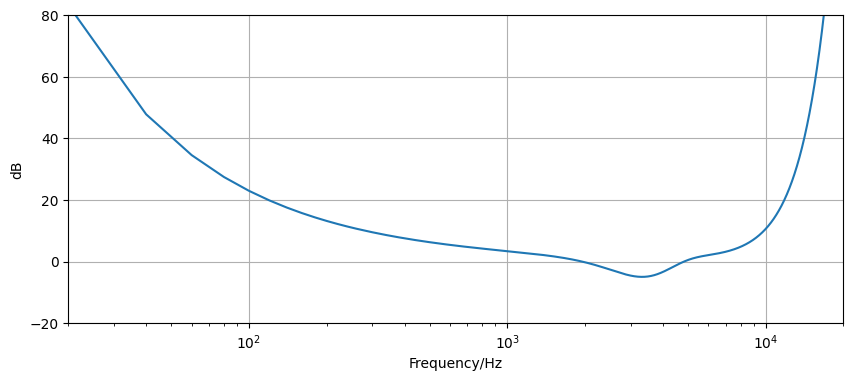

In [7]:
# compute and display the the threshold curve of quiet

f=np.linspace(20,20000,1000)
LTQ=3.64*(f/1000.)**-0.8 -6.5*np.exp(-0.6*(f/1000.-3.3)**2.)+1e-3*((f/1000.)**4.)
plt.figure(figsize=(10,4))
plt.semilogx(f,LTQ)
plt.axis([20,20000, -20,80])
plt.xlabel('Frequency/Hz')
plt.ylabel('dB')
plt.grid()

C:\Users\laiap\AppData\Local\Temp\ipykernel_20596\2925751355.py:5: RuntimeWarning: divide by zero encountered in power
  LTQ=np.clip((3.64*(f/1000.)**-0.8 -6.5*np.exp(-0.6*(f/1000.- 3.3)**2.)+1e-3*((f/1000.)**4.)),-20,60)


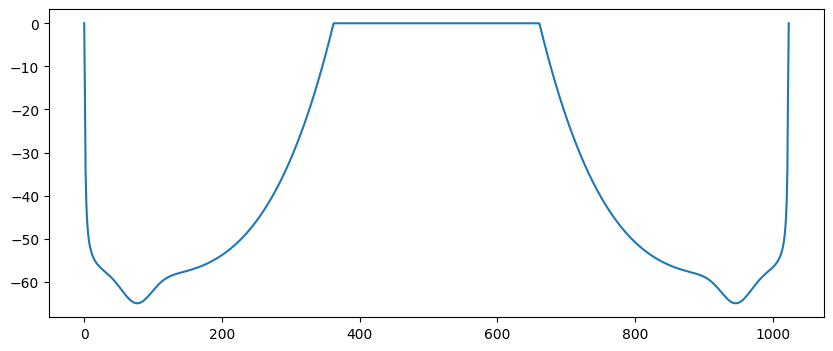

In [8]:
# adapt the magnitude threshold of quiet to a curve to be used in a spectrum
fs = 44100    # sampling frequency
N = 1024      # number of subbands
f = np.linspace(0,fs/2, N//2)
LTQ=np.clip((3.64*(f/1000.)**-0.8 -6.5*np.exp(-0.6*(f/1000.- 3.3)**2.)+1e-3*((f/1000.)**4.)),-20,60)
LTQ=np.append(LTQ-60, np.flip(LTQ-60))
plt.figure(figsize=(10,4))
plt.plot(LTQ)

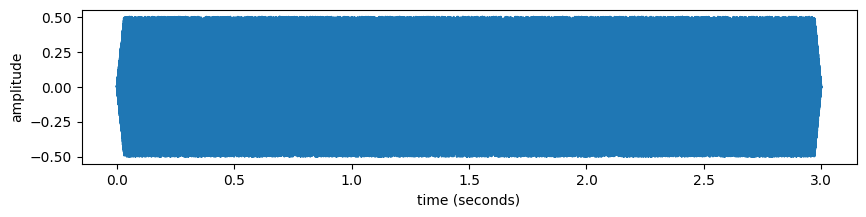

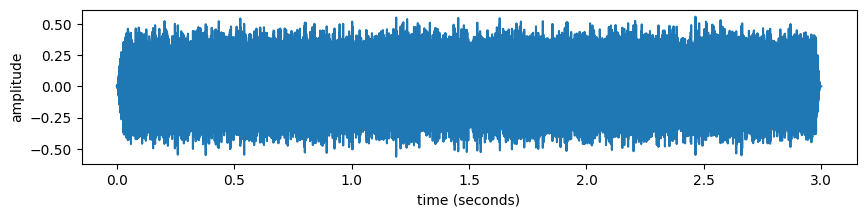

In [9]:
# apply the masking curve of quiet to a sound

x, fs = read_sound('../sounds/white-noise.wav')

y = np.zeros(len(x))
i = 0
while i < x.size-N:
  w = signal.get_window('hann', N)
  xw = x[i:i+N] * w
  X = fft(xw)
  mX = 20 * np.log10(abs(X))
  pX = np.angle(X)

  mX += LTQ
  Y = 10 ** (mX/20) * np.exp(1j * pX)
  yt = np.real(ifft(Y))
  y[i:i+N] += yt
  i += N//2

display_sound(x, fs)
display_sound(y, fs)

<font color=red> ***MY MODIFIED CODE*** </font>

C:\Users\laiap\AppData\Local\Temp\ipykernel_20596\714676318.py:10: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sampling_rate, x = read(file)


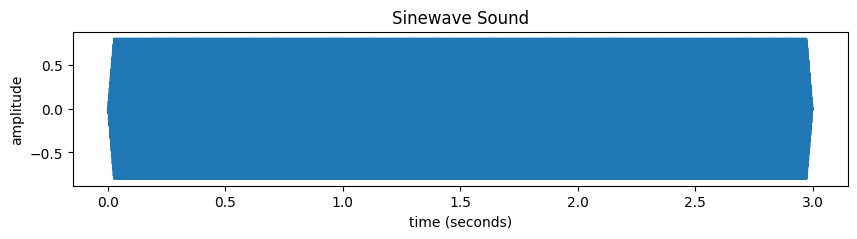

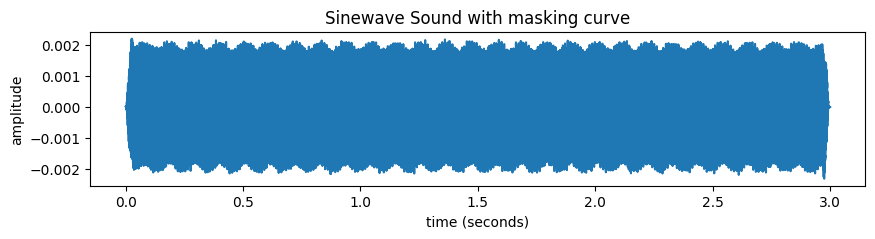

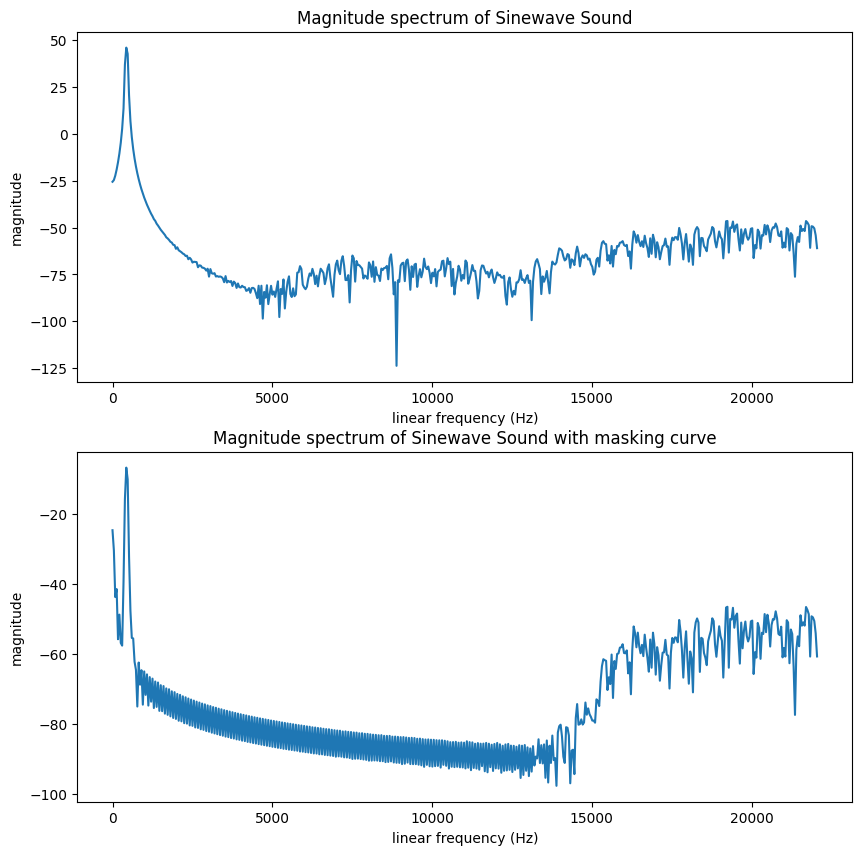

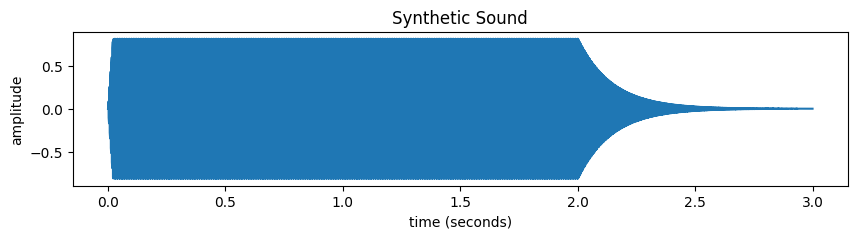

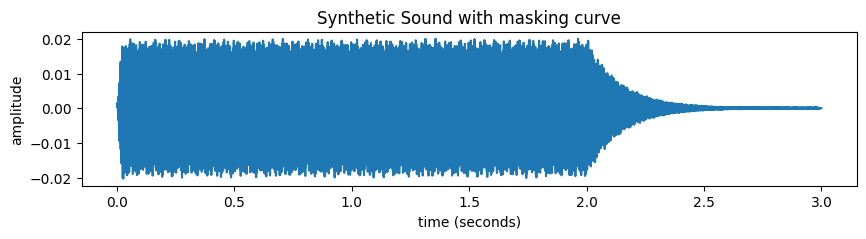

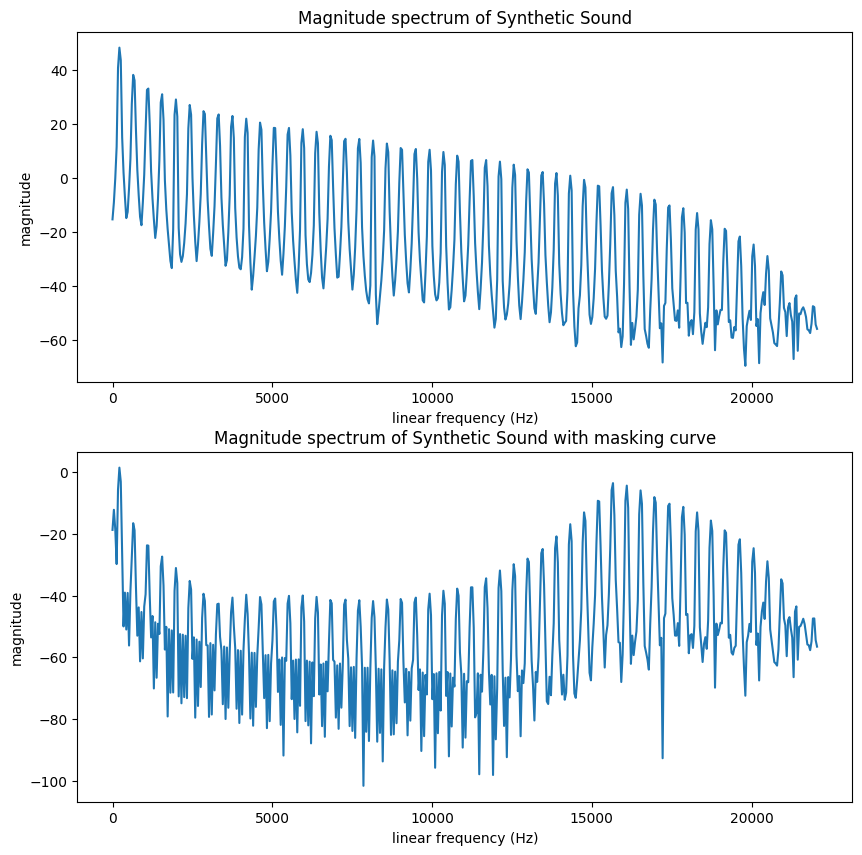

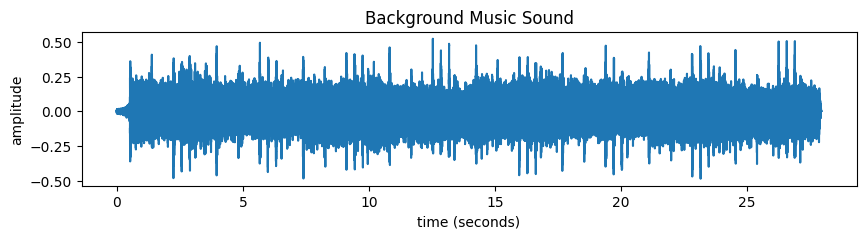

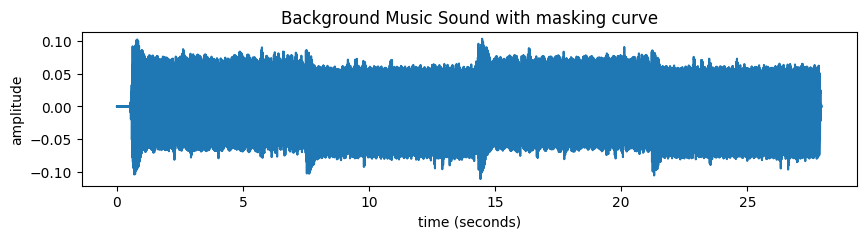

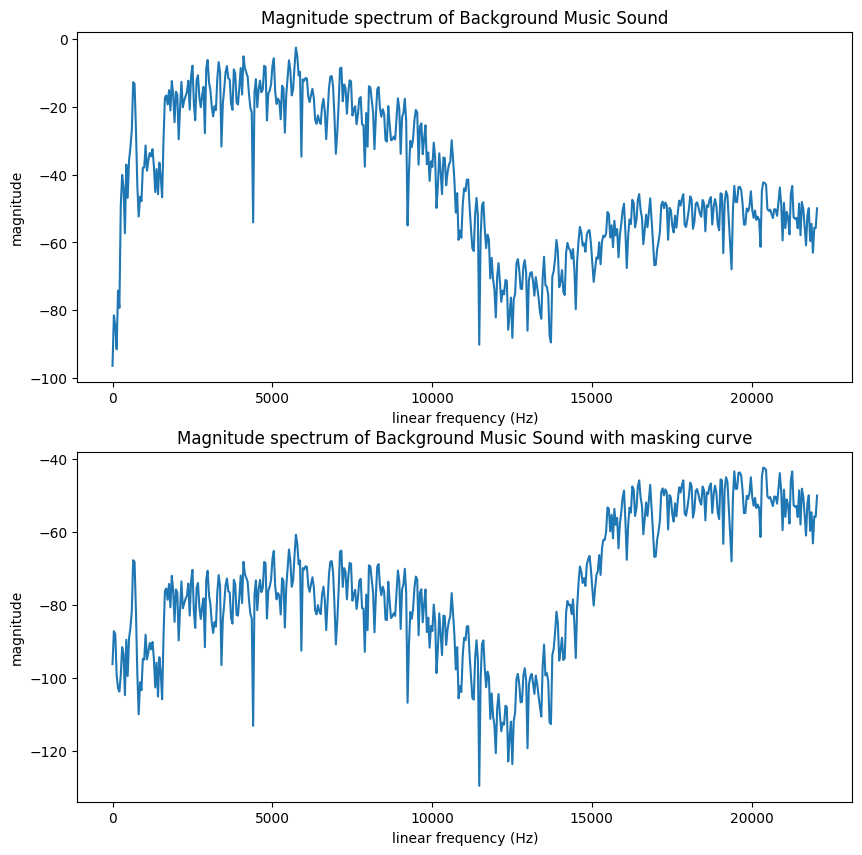

In [10]:
## APPLYING THE MASKING CURVE TO THE SOUNDS SINEWAVE, SYNTHETIC AND BACKGROUND MUSIC

# Step 01: Reading the sounds
x_sine, fs0 = read_sound('../sounds/sinewave.wav')
x_synth, fs1 = read_sound('../sounds/synthetic.wav')
x_bg, fs2 = read_sound('../sounds/750340-background-music.wav')
x_sounds = [x_sine, x_synth, x_bg]

# Step 02: Applying the masking curve
N = 1024
    # sinewave sound
y_sine = np.zeros(len(x_sine))
i=0
while i < x_sine.size-N:
        w = signal.get_window('hann', N)
        xw = x_sine[i:i+N] * w
        X = fft(xw)
        mX = 20 * np.log10(abs(X))
        pX = np.angle(X)

        mX += LTQ
        Y = 10 ** (mX/20) * np.exp(1j * pX)
        yt = np.real(ifft(Y))
        y_sine[i:i+N] += yt
        i += N//2

    # synthetic sound
y_synth = np.zeros(len(x_synth))
i = 0
while i < x_synth.size-N:
        w = signal.get_window('hann', N)
        xw = x_synth[i:i+N] * w
        X = fft(xw)
        mX = 20 * np.log10(abs(X))
        pX = np.angle(X)

        mX += LTQ
        Y = 10 ** (mX/20) * np.exp(1j * pX)
        yt = np.real(ifft(Y))
        y_synth[i:i+N] += yt
        i += N//2

    # background music sound
y_bg = np.zeros(len(x_bg))
i=0
while i < x_bg.size-N:
        w = signal.get_window('hann', N)
        xw = x_bg[i:i+N] * w
        X = fft(xw)
        mX = 20 * np.log10(abs(X))
        pX = np.angle(X)

        mX += LTQ
        Y = 10 ** (mX/20) * np.exp(1j * pX)
        yt = np.real(ifft(Y))
        y_bg[i:i+N] += yt
        i += N//2

# Step 03: Compute the magnitude spectrums
N = 1024
x1_sine = x_sine[10000:10000+N]
x1_synth = x_synth[10000:10000+N]
x1_bg = x_bg[10000:10000+N]
x1_sounds = [x1_sine, x1_synth, x1_bg]

y1_sine = y_sine[10000:10000+N]
y1_synth = y_synth[10000:10000+N]
y1_bg = y_bg[10000:10000+N]
y1_sounds = [y1_sine, y1_synth, y1_bg]

magnitude_spectrums_x = []
for x1 in x1_sounds:
    wx = signal.get_window('hann', N)
    spectrum_x = fft(wx*x1)
    mag_spec_x = 20*np.log10(abs(spectrum_x[:N//2]))
    magnitude_spectrums_x.append(mag_spec_x)

magnitude_spectrums_y = []
for y1 in y1_sounds:
    wx = signal.get_window('hann', N)
    spectrum_y = fft(wx*y1)
    mag_spec_y = 20*np.log10(abs(spectrum_y[:N//2]))
    magnitude_spectrums_y.append(mag_spec_y)


# Step 04: Displaying the sounds, and their magnitude spectrums
display_sound(x_sounds[0], fs0, "Sinewave Sound")
display_sound(y_sine, fs0, "Sinewave Sound with masking curve")

plt.figure(figsize=(10, 10))
plt.subplot(2,1,1)
frequency_indexes0 =np.linspace(0,fs0/2, N//2)
plt.plot(frequency_indexes0, magnitude_spectrums_x[0])
plt.title("Magnitude spectrum of Sinewave Sound")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")

plt.subplot(2,1,2)
plt.plot(frequency_indexes0, magnitude_spectrums_y[0])
plt.title("Magnitude spectrum of Sinewave Sound with masking curve")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")
plt.show()


display_sound(x_sounds[1], fs1, "Synthetic Sound")
display_sound(y_synth, fs1, "Synthetic Sound with masking curve")

plt.figure(figsize=(10, 10))

frequency_indexes1 =np.linspace(0,fs1/2, N//2)
plt.subplot(2,1,1)
plt.plot(frequency_indexes1, magnitude_spectrums_x[1])
plt.title("Magnitude spectrum of Synthetic Sound")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")

plt.subplot(2,1,2)
plt.plot(frequency_indexes1, magnitude_spectrums_y[1])
plt.title("Magnitude spectrum of Synthetic Sound with masking curve")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")
plt.show()

display_sound(x_sounds[2], fs2, "Background Music Sound")
display_sound(y_bg, fs2, "Background Music Sound with masking curve")

plt.figure(figsize=(10, 10))

frequency_indexes2 =np.linspace(0,fs2/2, N//2)
plt.subplot(2,1,1)
plt.plot(frequency_indexes2, magnitude_spectrums_x[2])
plt.title("Magnitude spectrum of Background Music Sound")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")

plt.subplot(2,1,2)
plt.plot(frequency_indexes2, magnitude_spectrums_y[2])
plt.title("Magnitude spectrum of Background Music Sound with masking curve")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")
plt.show()

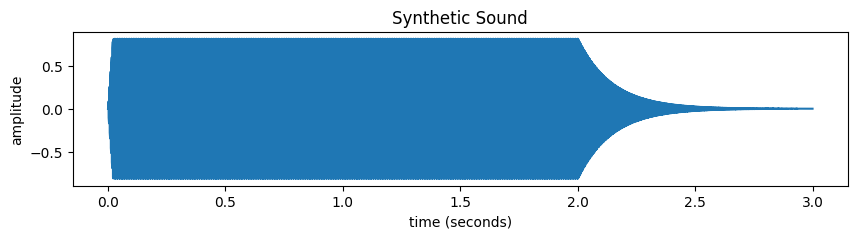

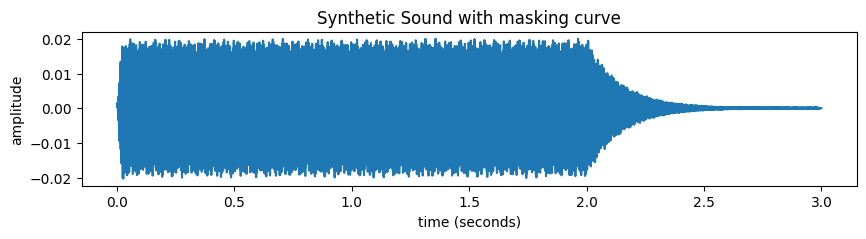

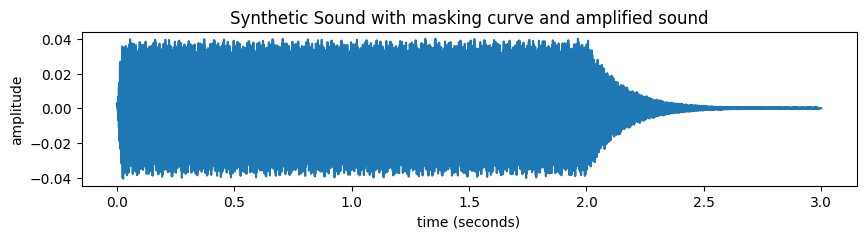

In [11]:
## AMPLIFYING THE SYNTHETIC  OUTPUT SOUND BY A FACTOR OF 2
display_sound(x_sounds[1], fs1, "Synthetic Sound")
display_sound(y_synth, fs1, "Synthetic Sound with masking curve")

amplified_synth = y_synth*2

display_sound(amplified_synth, fs1, "Synthetic Sound with masking curve and amplified sound")


**Questions:**

1. Apply the masking curve in quite to three different sounds with different characteristics (you choose). What do you hear? Does it result in the same effect for all of them? Explain. Support it with some spectral plots.

    <font color=red> I have chosen the sounds SINEWAVE, SYNTHETIC and BACKGROUND MUSIC. 
    - The sinewave sound is the simplest of all, since it is almost formed by a pure sinewave.
    - The synthetic sound is constant over time and amplitude, but it contains several harmonics, which makes it more complex.
    - And lastly, the background music sound contains so many frequencies and varies so much over time that it is the most complex of all.

    With this simple perception, we can assume that the sinewave sound after applying the masking curve will result in the same sound but extremely lower, whereas the other 2 sounds will contain some artifacts, whether it is slight noise, or just no recognition of the original sound.
    
    To analyze this correctly, for every sound I have shown its original waveform with the resulting sound waveform, and the original magnitude spectrum with linear frequency with the magnitude spectrum of the resulting sound.

    So, for the sinewave sound:
    - I had to put my headphones on 100% volume to be able to hear it decently, but I do not perceive any kind of distortion, rather than it is extremely low. However, that was expected, since what we are doing in this exercise is actually mantaining the section of the signal that is below the threshold curve of quiet, meaning that with the loudness that we can hear the original signal (20%), we will not hear it with the resulting one.

    - In the spectogram we can see that frequencies have been reduced in magnitude following exactly the threshold curve of quiet. The fundamental frequency has been reduced about -50 dBs, and that is why we can still hear it if we increase the volume. There are some frequencies that have been "erradicated" since they have been reduced more than 80dBs, but this signal being a simple sinewave, it did not result in any artifacts.

    For the synthetic sound:
    - We can actually hear it a little bit more than the sinewave, however, there are some artifacts on the sound. We can hear an annoying ringing, that is, a high frequency that is constant over the sound. This signal was more complex, so the threshold curve of quiet affects more when applied to the signal, and that is why we can hear some harmonics (frequencies) higher than others.

    - In the spectogram we can see how some of the lowest frequencies have been slightly reduced again (about 40-50 dBs), whereas the middle frequencies the frequencies from the range (5000-1500) have been extremely decreased, and from 15000 Hz they have the same magnitude. That is why we hear the ringing, because it belongs to one of those high frequencies that have barely been modified and that were too low on the original sound to notice, but now that we have increased the volume, we can hear them.

    Lastly, for the background sound:
    - We can only hear the lowest of frequencies, and everything is extremely distorted, we cannot recognize the sound, but we can recognize some parts of it (the low hits that it does). Since this application of the threshold curve mantains most the lowest and highest frequencies of the sound, and this particular sound has very low high frequencies, we can only perceive the low ones, even if it is louder than on the previous 2 sounds.

    - On the spectogram we can see how some of the lowest frequencies have been mantained, whereas all the middle ones have been decreased too much to be heard.

    So in conclusion, the mor ecomplex the sound, the worse it will be its resulting sound. The frequencies existing in the sound also have a great effect on how the resulting one will be perceived. 
    
    If the sinewave signal had a pure frequency between 5000 Hz and 1000 Hz we probably would not have been able to hear anything, since it would have been on the section that needs more loudness to be heard, therefore, when getting only the lower part of the signal of the threshold curve of quiet, it would have been greatly decreased and not hearable/perceivable at all.
    </font>

2. Amplify one of the output sounds by a factor of 2. Any difference? describe. 

    <font color=red> I have decided to apply it to the sound of the sinewave, since it was the less complex. 
    
    There is some difference, but not enough.

    This time I can hear it perfectly at a lower volume, however, the ringing is still present. This makes sense, since the threshold is still applied. Then, if I apply a factor of 2 to the output, I apply it to all the frequencies. 
    
    Only when the sound is very low in volume (in my headphones) I do not hear the ringing, but I also lose a lot of more harmonics and I perceive the sound extremely similar to a "pure" sinewave.</font>
____

# Part 3 - Frequency masking
Explore frequency masking. Answer the questions given and modify the code as needed to support your answers.

In [12]:
def f_SP_dB(maxfreq,nfilts):
    #usage: spreadingfunctionmatdB=f_SP_dB(maxfreq,nfilts)
    #computes the spreading function protoype, in the Bark scale.
    #Arguments: maxfreq: half the sampling freqency
    #nfilts: Number of subbands in the Bark domain, for instance 64

    maxbark=hz2bark(maxfreq) #upper end of our Bark scale:22 Bark at 16 kHz

    #Number of our Bark scale bands over this range: nfilts=64
    spreadingfunctionBarkdB=np.zeros(2*nfilts)

    #Spreading function prototype, "nfilts" bands for lower slope
    spreadingfunctionBarkdB[0:nfilts]=np.linspace(-maxbark*27,-8,nfilts)-23.5

    #"nfilts" bands for upper slope:
    spreadingfunctionBarkdB[nfilts:2*nfilts]=np.linspace(0,-maxbark*12.0,nfilts)-23.5
    return spreadingfunctionBarkdB

def mapping2bark(mX,W,nfft):
    #Maps (warps) magnitude spectrum vector mX from DFT to the Bark scale
    #arguments: mX: magnitude spectrum from fft
    #W: mapping matrix from function mapping2barkmat
    #nfft: : number of subbands in fft
    #returns: mXbark, magnitude mapped to the Bark scale

    nfreqs= nfft//2

    #Here is the actual mapping, suming up powers and conv. back to Voltages:
    mXbark = (np.dot( np.abs(mX[:nfreqs])**2.0, W[:, :nfreqs].T))**(0.5)

    return mXbark

def mappingfrombark(mTbark,W_inv,nfft):
    #usage: mT=mappingfrombark(mTbark,W_inv,nfft)
    #Maps (warps) magnitude spectrum vector mTbark in the Bark scale
    # back to the linear scale
    #arguments:
    #mTbark: masking threshold in the Bark domain
    #W_inv : inverse mapping matrix W_inv from matrix W for mapping back from bark scale
    #nfft: : number of subbands in fft
    #returns: mT, masking threshold in the linear scale

    nfreqs = nfft//2
    mT = np.dot(mTbark, W_inv[:, :nfreqs].T)
    return mT

def maskingThresholdBark(mXbark,spreadingfuncmatrix,alpha,fs,nfilts):
    #Computes the masking threshold on the Bark scale with non-linear superposition
    #usage: mTbark=maskingThresholdBark(mXbark,spreadingfuncmatrix,alpha)
    #Arg: mXbark: magnitude of FFT spectrum, on the Bark scale
    #spreadingfuncmatrix: spreading function matrix from function spreadingfunctionmat
    #alpha: exponent for non-linear superposition (eg. 0.6),
    #fs: sampling freq., nfilts: number of Bark subbands
    #nfilts: Number of subbands in the Bark domain, for instance 64
    #Returns: mTbark: the resulting Masking Threshold on the Bark scale

    #Compute the non-linear superposition:
    mTbark = np.dot(mXbark**alpha, spreadingfuncmatrix**alpha)

    #apply the inverse exponent to the result:
    mTbark = mTbark**(1.0/alpha)

    #Threshold in quiet:
    maxfreq = fs/2.0
    maxbark = hz2bark(maxfreq)
    step_bark = maxbark/(nfilts-1)
    barks=np.arange(0,nfilts)*step_bark

    #convert the bark subband frequencies to Hz:
    f=bark2hz(barks)+1e-6
    #Threshold of quiet in the Bark subbands in dB:
    LTQ=np.clip((3.64*(f/1000.)**-0.8 -6.5*np.exp(-0.6*(f/1000.-3.3)**2.)+1e-3*((f/1000.)**4.)),-20,160)
    #Maximum of spreading functions and hearing threshold in quiet:
    mTbark=np.max((mTbark, 10.0**((LTQ-60)/20)),0)
    return mTbark

def mapping2barkmat(fs, nfilts, nfft):
  #Constructing matrix W which has 1’s for each Bark subband, and 0’s else:
  #nfft=2048; nfilts=64;
  nfreqs=nfft//2
  maxfreq = fs/2.0
  maxbark = hz2bark(maxfreq)
  step_barks = maxbark/(nfilts-1)
  #the linspace produces an array with the fft band edges:
  binbarks = hz2bark(np.linspace(0,(nfft//2),(nfft//2)+1)*fs/nfft)
  W = np.zeros((nfilts, nfft))
  for i in range(nfilts):
    W[i,0:(nfft//2)+1] = (np.round(binbarks/step_barks)== i)
  return W

def mappingfrombarkmat(W,nfft):
    #Constructing inverse mapping matrix W_inv from matrix W for mapping back from bark scale
    #usuage: W_inv=mappingfrombarkmat(Wnfft)
    #argument: W: mapping matrix from function mapping2barkmat
    #nfft: : number of subbands in fft
    nfreqs=int(nfft/2)
    W_inv= np.dot(np.diag((1.0/np.sum(W,1))**0.5), W[:,0:nfreqs + 1]).T
    return W_inv

def spreadingfunctionmat(spreadingfunctionBarkdB, alpha, nfilts):
    #Turns the spreading prototype function into a matrix of shifted versions.
    #Convert from dB to "voltage" and include alpha exponent
    #nfilts: Number of subbands in the Bark domain, for instance 64
    spreadingfunctionBarkVoltage=10.0**(spreadingfunctionBarkdB/20.0*alpha)

    #Spreading functions for all bark scale bands in a matrix:
    spreadingfuncmatrix=np.zeros((nfilts,nfilts))

    for k in range(nfilts):
        spreadingfuncmatrix[k,:]=spreadingfunctionBarkVoltage[(nfilts-k):(2*nfilts-k)]

    return spreadingfuncmatrix

C:\Users\laiap\AppData\Local\Temp\ipykernel_20596\714676318.py:10: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sampling_rate, x = read(file)


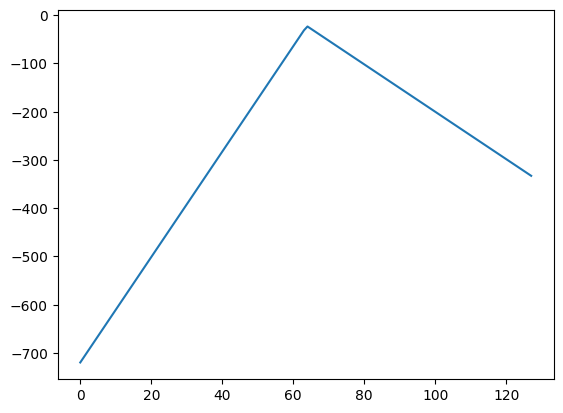

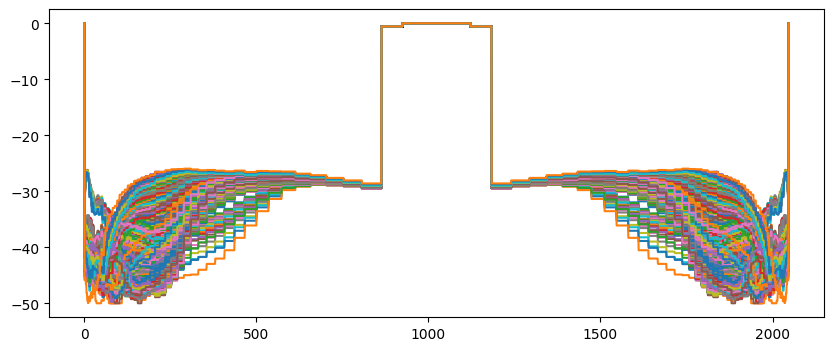

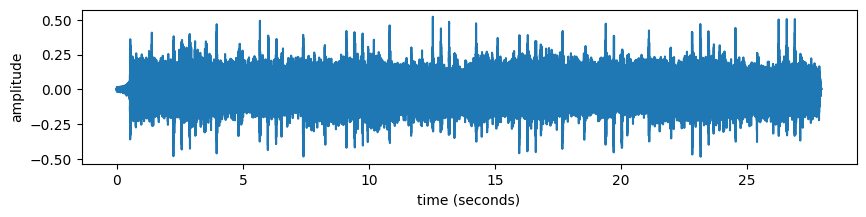

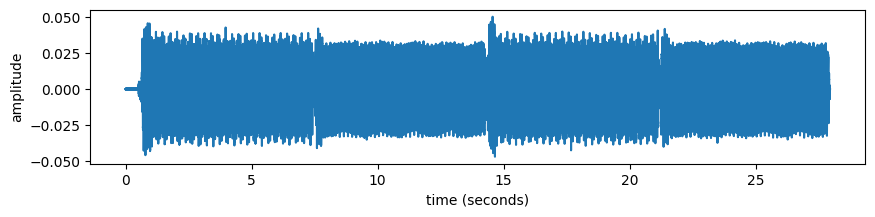

In [13]:
# compute the frequency masking curve for each frame of a sound and subtract it from the sound
x, fs = read_sound('../sounds/750340-background-music.wav')

# compute the 
maxfreq = fs/2
alpha = 0.8 # exponent for non-linear superposition
nfilts = 64
N = 2048
W = mapping2barkmat(fs, nfilts, N)
W_inv = mappingfrombarkmat(W, N)
spreadingfunctionBarkdB=f_SP_dB(maxfreq, nfilts)
plt.plot(spreadingfunctionBarkdB)
spreadingfuncmatrix=spreadingfunctionmat(spreadingfunctionBarkdB, alpha, nfilts)

plt.figure(figsize=(10,4))
y = np.zeros(len(x))

# iterate over the sound
i = 0
while i < x.size-N:
  w = signal.get_window('hann', N)
  xw = x[i:i+N] * w
  X = fft(xw)
  mX = 20 * np.log10(abs(X))
  pX = np.angle(X)

  # Compute the Bark scale magnitude spectrum
  mXbark = mapping2bark(mX, W, N)
  # Compute the masking threshold in the Bark domain:
  mTbark =  maskingThresholdBark(mXbark, spreadingfuncmatrix, alpha, fs, nfilts)
  # Masking threshold in the original frequency domain
  mT = 20 * np.log10(mappingfrombark(mTbark, W_inv, N))
  masking_curve = np.append(mT, np.flip(mT[:N//2-1])) - 60
  masking_curve = np.clip(masking_curve,-50,0)
  mX += masking_curve
  plt.plot(masking_curve)
  Y = 10 ** (mX/20) * np.exp(1j * pX)
  yt = np.real(ifft(Y))
  y[i:i+N] += yt
  i += N//2

display_sound(x, fs)
display_sound(y, fs)

<font color=red> ***MY MODIFIED CODE*** </font>

In [14]:
def display_spectrogram(sound_array, hop_size=256, fft_size=512, sampling_rate=44100, title=None):
  """ Display magnitude spectrogram of signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      hop_size (int): window hop size
      fft_size (int): Spectrogram fft size
      sampling_rate (int): Sampling rate of sound
  """
  sample_index = 0
  window = signal.get_window('hann', fft_size)
  magnitude_spectrogram = []
  while sample_index < sound_array.size-fft_size:
    spectrum = fft(window*sound_array[sample_index:sample_index+fft_size])
    magnitude_spectrum= 20*np.log10(abs(spectrum[:spectrum.size//2]))
    magnitude_spectrogram.append(magnitude_spectrum)
    sample_index += hop_size

  plt.figure(figsize=(10, 5))
  time_indexes = np.arange(0, sample_index/sampling_rate, hop_size/sampling_rate)
  frequency_indexes = np.arange(0, sampling_rate/2, sampling_rate/fft_size)
  plt.pcolormesh(time_indexes, frequency_indexes, np.transpose(magnitude_spectrogram), shading='nearest', cmap='inferno')
  plt.colorbar(format='%+2.0f dB')
  plt.xlabel('time (seconds)')
  plt.ylabel('frequency (Hz)')
  plt.title(title)
  plt.show()

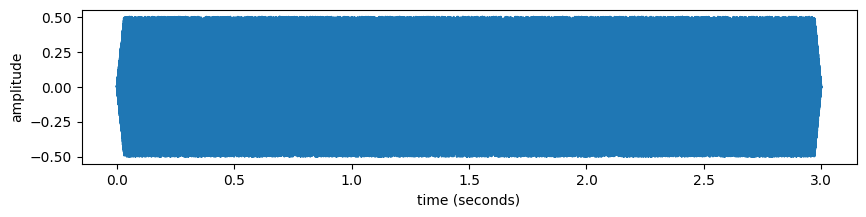

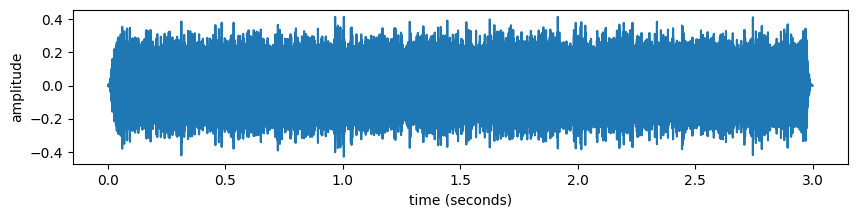

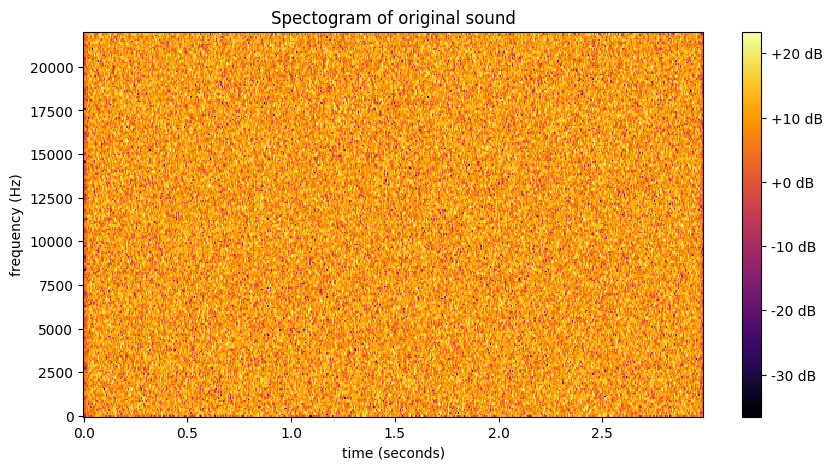

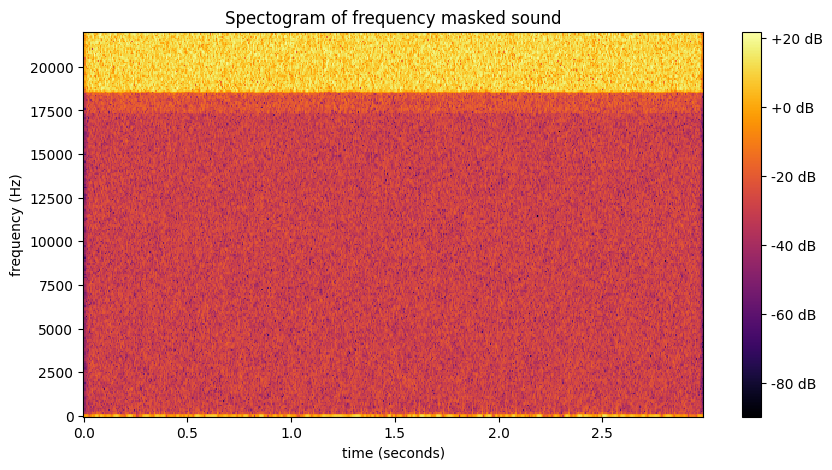

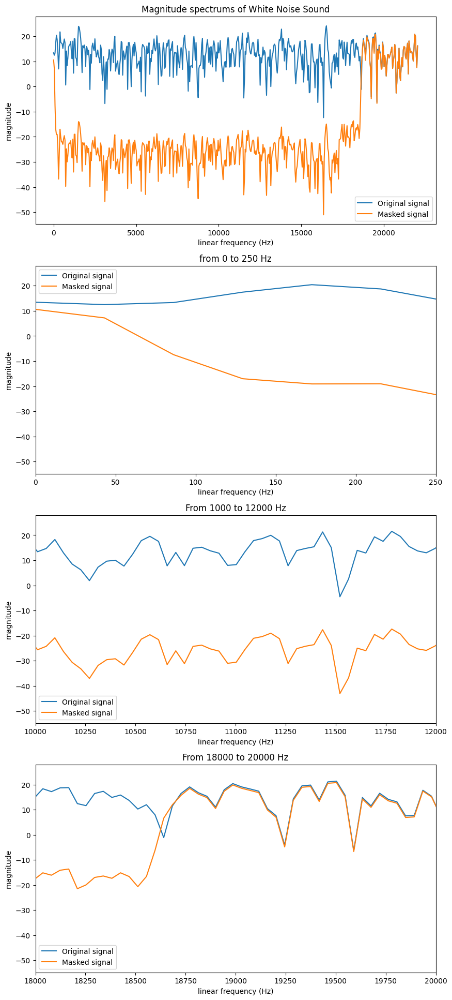

In [15]:
## APPLYING FREQUENCY MASKING TO THE SOUND WHITE NOISE , DISPLAYING ITS INPUT AND OUTPUT SPECTOGRAM
## AND SUPERPOSING THE INPUT AND OUTPUT SPECTRUM OF A PARTICULAR SECTION OF THE SOUND

# Step 01: Reading the sound
x, fs = read_sound('../sounds/white-noise.wav')

# Step 02: Appying frequency masking
    #variables
maxfreq = fs/2
alpha = 0.8
nfilts = 64
N = 2048
y = np.zeros(len(x))

    #functions
W = mapping2barkmat(fs, nfilts, N)
W_inv = mappingfrombarkmat(W, N)
spreadingfunctionBarkdB=f_SP_dB(maxfreq, nfilts)
spreadingfuncmatrix=spreadingfunctionmat(spreadingfunctionBarkdB, alpha, nfilts)

    #iterate over the sound
i = 0
while i < x.size-N:
  w = signal.get_window('hann', N)
  xw = x[i:i+N] * w
  X = fft(xw)
  mX = 20 * np.log10(abs(X))
  pX = np.angle(X)

    #Bark scale magnitude spectrum
  mXbark = mapping2bark(mX, W, N)

    #Masking threshold in Bark domain
  mTbark =  maskingThresholdBark(mXbark, spreadingfuncmatrix, alpha, fs, nfilts)

    #Masking threshold in original freq domain
  mT = 20 * np.log10(mappingfrombark(mTbark, W_inv, N))
  masking_curve = np.append(mT, np.flip(mT[:N//2-1])) - 60
  masking_curve = np.clip(masking_curve,-50,0)
  mX += masking_curve

  Y = 10 ** (mX/20) * np.exp(1j * pX)
  yt = np.real(ifft(Y))
  y[i:i+N] += yt
  i += N//2

# Step 03: Displaying the input and output spectograms
display_sound(x,fs)
display_sound(y,fs)

# Step 04: Displaying the input and output spectograms
display_spectrogram(x,256,512,fs,"Spectogram of original sound")
display_spectrogram(y,256,512,fs,"Spectogram of frequency masked sound")

# Step 05: Displaying the magnitude spectrum of input and output of a particular section of the sound
  #variables

N = 1024
x1 = x[10000:10000+N]
y1 = y[10000:10000+N]

wx = signal.get_window('hann', N)
spectrum_x = fft(wx*x1)
mag_spec_x = 20*np.log10(abs(spectrum_x[:N//2]))

wy = signal.get_window('hann', N)
spectrum_y = fft(wy*y1)
mag_spec_y = 20*np.log10(abs(spectrum_y[:N//2]))

plt.figure(figsize=(10, 24))

frequency_indexes =np.linspace(0,fs/2, N//2)
plt.subplot(4,1,1)
plt.plot(frequency_indexes, mag_spec_x, label="Original signal")
plt.plot(frequency_indexes,mag_spec_y, label="Masked signal")
plt.title("Magnitude spectrums of White Noise Sound")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")
plt.legend()

plt.subplot(4,1,2)
plt.plot(frequency_indexes, mag_spec_x, label="Original signal")
plt.plot(frequency_indexes,mag_spec_y, label="Masked signal")
plt.title("from 0 to 250 Hz")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")
plt.legend()
plt.xlim(0, 250)

plt.subplot(4,1,3)
plt.plot(frequency_indexes, mag_spec_x, label="Original signal")
plt.plot(frequency_indexes,mag_spec_y, label="Masked signal")
plt.title("From 1000 to 12000 Hz")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")
plt.legend()
plt.xlim(10000, 12000)

plt.subplot(4,1,4)
plt.plot(frequency_indexes, mag_spec_x, label="Original signal")
plt.plot(frequency_indexes,mag_spec_y, label="Masked signal")
plt.title("From 18000 to 20000 Hz")
plt.xlabel("linear frequency (Hz)")
plt.ylabel("magnitude")
plt.legend()
plt.xlim(18000, 20000)
plt.show()

**Questions:**

1. Apply frequency masking to one sound you choose. Compute and display the spectrogram of both the input and output sounds. Superpose, in the same plot, the magnitude spectrum of a particular section of the input sound with the magnitude spectrum of the same time location of the output sound. Explain the difference between the two spectrograms and the two spectra.

    <font color=red> 
    
    We measure the amount of 
    I have decided to apply frequency masking to the sound WHITE NOISE. 
    I chose this sound because it can be described as a constant sounds that has all the range of frequencies at approximately the same magnitude throughout all the sound. Therefore, in the spectogram it will be clearly shown which are the range of frequencies that habe been decreased, and by how much. 
    
    We start by showing both waveforms, and we can already see how although the amplitude is very similar, the resulting sound is much more less smooth than the original, since some frequencies are greatly decreased.

    Perceivably speaking, the resulting sound it is less loud, and higher pitched.
    
    On the spectograms we can see on the original how all frequencies are at approximately the same color, that is, the same intensity, and throughout the whole duration of the sound. 
    
    On the other spectogram the situation is very different:
    - We can see how only the lowest of frequencies (0-100 Hz approximately) have been mantained on the same intensity, and the highest range (18750-22050 Hz) too. 

    - We can also see that from frequency 17500 to frequency 18750 Hz approximately, they have been reduced, but not as much as the rest of frequencies. They have been reduced approximately 30 dB, whereas all the rest of frequencies have been reduced about -40 to -50 dBs.

    And moving on to the spectrums:
    
    We first plotted the full spectrum, and then we plotted different parts of it according to what we analyzed on the spectogram. At a first glance, we already can see that we were wrong mentioning that the masked signal mantained the lowest frequencies. 

    - On the spectrum from 0 to 250 Hz we can see how on the very first frequencies the amplitude is almost the same until 45-50Hz, then it keeps decreasing until arriving at a constant of -30 dBs.

    - On the spectrum from 10000 to 12000 Hz we can see how the masked signal is still lower in amplitude, but this time is by approximately 40 dBs lower, just as mentioned on the spectogram for the frequencies between 300 and 18000 Hz. (On the spectogram we said the intensity was mantained until 100 Hz but we now know that was wrong, but that until 250 Hz the frequencies' intensity has not been reduced by 40 dBs).

    - And lastly, on the spectrum from 18000 to 20000 Hz we can see how from 18000 to 18750 Hz the intensity of the masked signal is increasing (actually being less lowered) until it gets to being exactly the same intensity as the original signal until the end of frequencies.

    Frequency masking is about getting the tone with most intensity for each critical band, and then applying this frequency masking. Some range of frequencies will be lowered more in intensity than others. However, the teacher mentioned that overall we shoudl get more or less the same spectrum, but with lower intensity, and this is exactly what we are getting. If we did not zoom in into different range of frequencies we would have thought that the decrease in energy (intensity/dBs) would have been exactly the same for all frequencies, except for the highest ones.
    </font>
___